## 2. Topic Selection:

# Trip Planner Agent - GTHolidays

# 3. Problem Definition:



1. Problem statment:

> International students and travellers new to United States of America, often find it difficult to plan a trip. They either think of inviting a friend to a common place, then begin the journey from a single source of city and then plan trip around it. Additionally, we also have a hard time to organize a trip with no or little details about accurate time, cost and aesthetic based factors.
So I am building an agent that plan's a good itinerary, producing a fair, budget-friendly meetup plan from destination to itinerary.

2. Target Audience: The intended audience of this project are Internationals - students, travellers, New to US.

3. Tasks:

> Recommendations for group of 3 triangularly placed friends (Chicago, Florida and Maryland).

> Hotels cheaper w.r.t veg and non-vegetarian restraunts.

> Budget-based itinerary, carefully evaluating their options and choice of place to visit.

# 4. Setup

In [87]:
!pip install -qU langchain langgraph langsmith langchain-groq pillow

In [88]:
!pip install -qU langchain-huggingface

Testing the groq and langsmith api key

In [89]:
import os
from google.colab import userdata
from langsmith import Client

langsmith_key = userdata.get('Langsmith_Key')
client1 = Client(api_key=langsmith_key)

try:
  projects = list(client1.list_projects())
  print(f'API calls successful...{len(projects)} are found.')
except Exception as e:
  print('API calls fails..')


API calls successful...1 are found.


Testing trace

In [90]:
project_name = 'GTHolidays'
project = client1.create_project(project_name=project_name, upsert=True)


In [91]:
langsmith_key = userdata.get('Langsmith_Key')
client1 = Client(api_key=langsmith_key)

try:
  projects = list(client1.list_projects())

  has_project = any(getattr(obj, 'name', None) == project_name for obj in projects)
  print(f'Langsmith project {project_name}? {'Yes' if has_project else 'No'}')
except Exception as e:
  print('API call failed.')
  print(f'{e}')

Langsmith project GTHolidays? Yes


In [92]:
from langsmith import Client, traceable, tracing_context
@traceable
def task(prompt):
  return f'Response to {prompt}'

with tracing_context(client=client1, project_name=project_name, enabled=True):
  task('Testing langsmith tracing from colab')

# Load key and test connection

In [121]:
import os
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

os.environ['HUGGINGFACE_API'] = userdata.get('HF_TOKEN')
REASONING_MODEL = 'openai/gpt-oss-120b'
hf_test = ChatHuggingFace(
    llm=HuggingFaceEndpoint(
        repo_id=REASONING_MODEL, provider='auto', max_new_tokens=200

))
print(hf_test.invoke("What is the highest tourist visited u.s city?").content)

**The most‑visited city in the United States is New York City.**  

| Rank (2023‑2024) | City | Approx. International + Domestic Visitors* |
|------------------|------|--------------------------------------------|
| 1 | New York City, NY | **≈ 66 million** |
| 2 | Los Angeles, CA | ≈ 45 million |
| 3 | Orlando (including the Disney/Universal area), FL | ≈ 44 million |
| 


In [122]:
import os
from langchain_groq import ChatGroq

os.environ['GROQ_API_KEY'] = userdata.get('groq1')

VISION_MODEL = 'qwen/qwen3.8-27b'
#REASONING_MODEL = 'openai/gpt-oss-120b'

test_llm_call = ChatGroq(
    model=VISION_MODEL
)
response = test_llm_call.invoke('In a sentence, name one city in Maryland')
print(response.content)

Baltimore is a major city located in the state of Maryland.


In [123]:
trace_test_1 = test_llm_call.invoke('Name a veg restraunt in gainsville florida')
print(trace_test_1.content)

A popular vegan option in Gainesville, Florida, is **The Vegan Bottle**.

It is a well-known local spot that serves a wide variety of vegan dishes, including burgers, sandwiches, pizza, and desserts. Another highly rated alternative is **Vegan Outfitters**, which offers creative plant-based meals and is also quite popular with locals and visitors.

Both are located in downtown or near the University of Florida area, making them accessible for students and tourists alike.


In [124]:
from langsmith import Client

trace_test_2 = test_llm_call.invoke('Name a popular spring break state in united states!')
print(f'Model reply: {trace_test_2.content}')

client1 = Client(api_key= langsmith_key)
recent_runs = list(client1.list_runs(project_name=project_name,limit=10))
for r in recent_runs:
  print(r.name, r.run_type, r.status)


Model reply: Florida is widely considered the most popular state for spring break in the United States.

Key destinations within Florida include:
*   **Orlando**: Center of major theme parks.
*   **Miami and South Florida**: Famous for its beaches, nightlife, and vibrant culture.
*   **Tampa Bay Area**: Popular for beach parties and a more relaxed vibe.

Other popular spring break states include **California** (especially Southern California beaches like Long Beach and San Diego) and **Hawaii**.


/tmp/ipykernel_1436/1089890115.py:7: DeprecationWarning: list_runs() is deprecated and will be removed after Jan 31, 2027. Use client.runs.query() instead. See https://docs.langchain.com/langsmith/smithdb-sdk-migration-query-runs#runs-query for the migration guide.
  recent_runs = list(client1.list_runs(project_name=project_name,limit=10))


ChatGroq llm success
task chain success
ChatGroq llm success
ChatGroq llm error
ChatGroq llm success
task chain success
ChatGroq llm success
task chain success
ChatGroq llm success
task chain success


In [125]:
def traced():
  ''' Every block is traced in the project'''
  return tracing_context(client=client1, project_name=project_name, enabled=True)

In [126]:
with traced():
  trace_testing = test_llm_call.invoke('Name a popular spring break state in united states!')
  print(f'Model reply: {trace_testing.content}')


Model reply: Florida is widely considered the most popular state for spring break in the United States.

Its warm weather, extensive coastline, and famous destinations like Miami, Daytona Beach, and Orlando make it a top choice for students and tourists seeking beach activities, nightlife, and amusement parks during the spring break season.


In [127]:
try:
  recent_runs = list(client1.list_runs(project_name=project_name,limit=10))
  for r in recent_runs:
    print(r.name, r.run_type, r.status)
except Exception as e:
  print(f'API call failed.')


/tmp/ipykernel_1436/2780456130.py:2: DeprecationWarning: list_runs() is deprecated and will be removed after Jan 31, 2027. Use client.runs.query() instead. See https://docs.langchain.com/langsmith/smithdb-sdk-migration-query-runs#runs-query for the migration guide.
  recent_runs = list(client1.list_runs(project_name=project_name,limit=10))


ChatGroq llm success
task chain success
ChatGroq llm success
ChatGroq llm error
ChatGroq llm success
task chain success
ChatGroq llm success
task chain success
ChatGroq llm success
task chain success


# Output for Traceability:

for trace_testing call

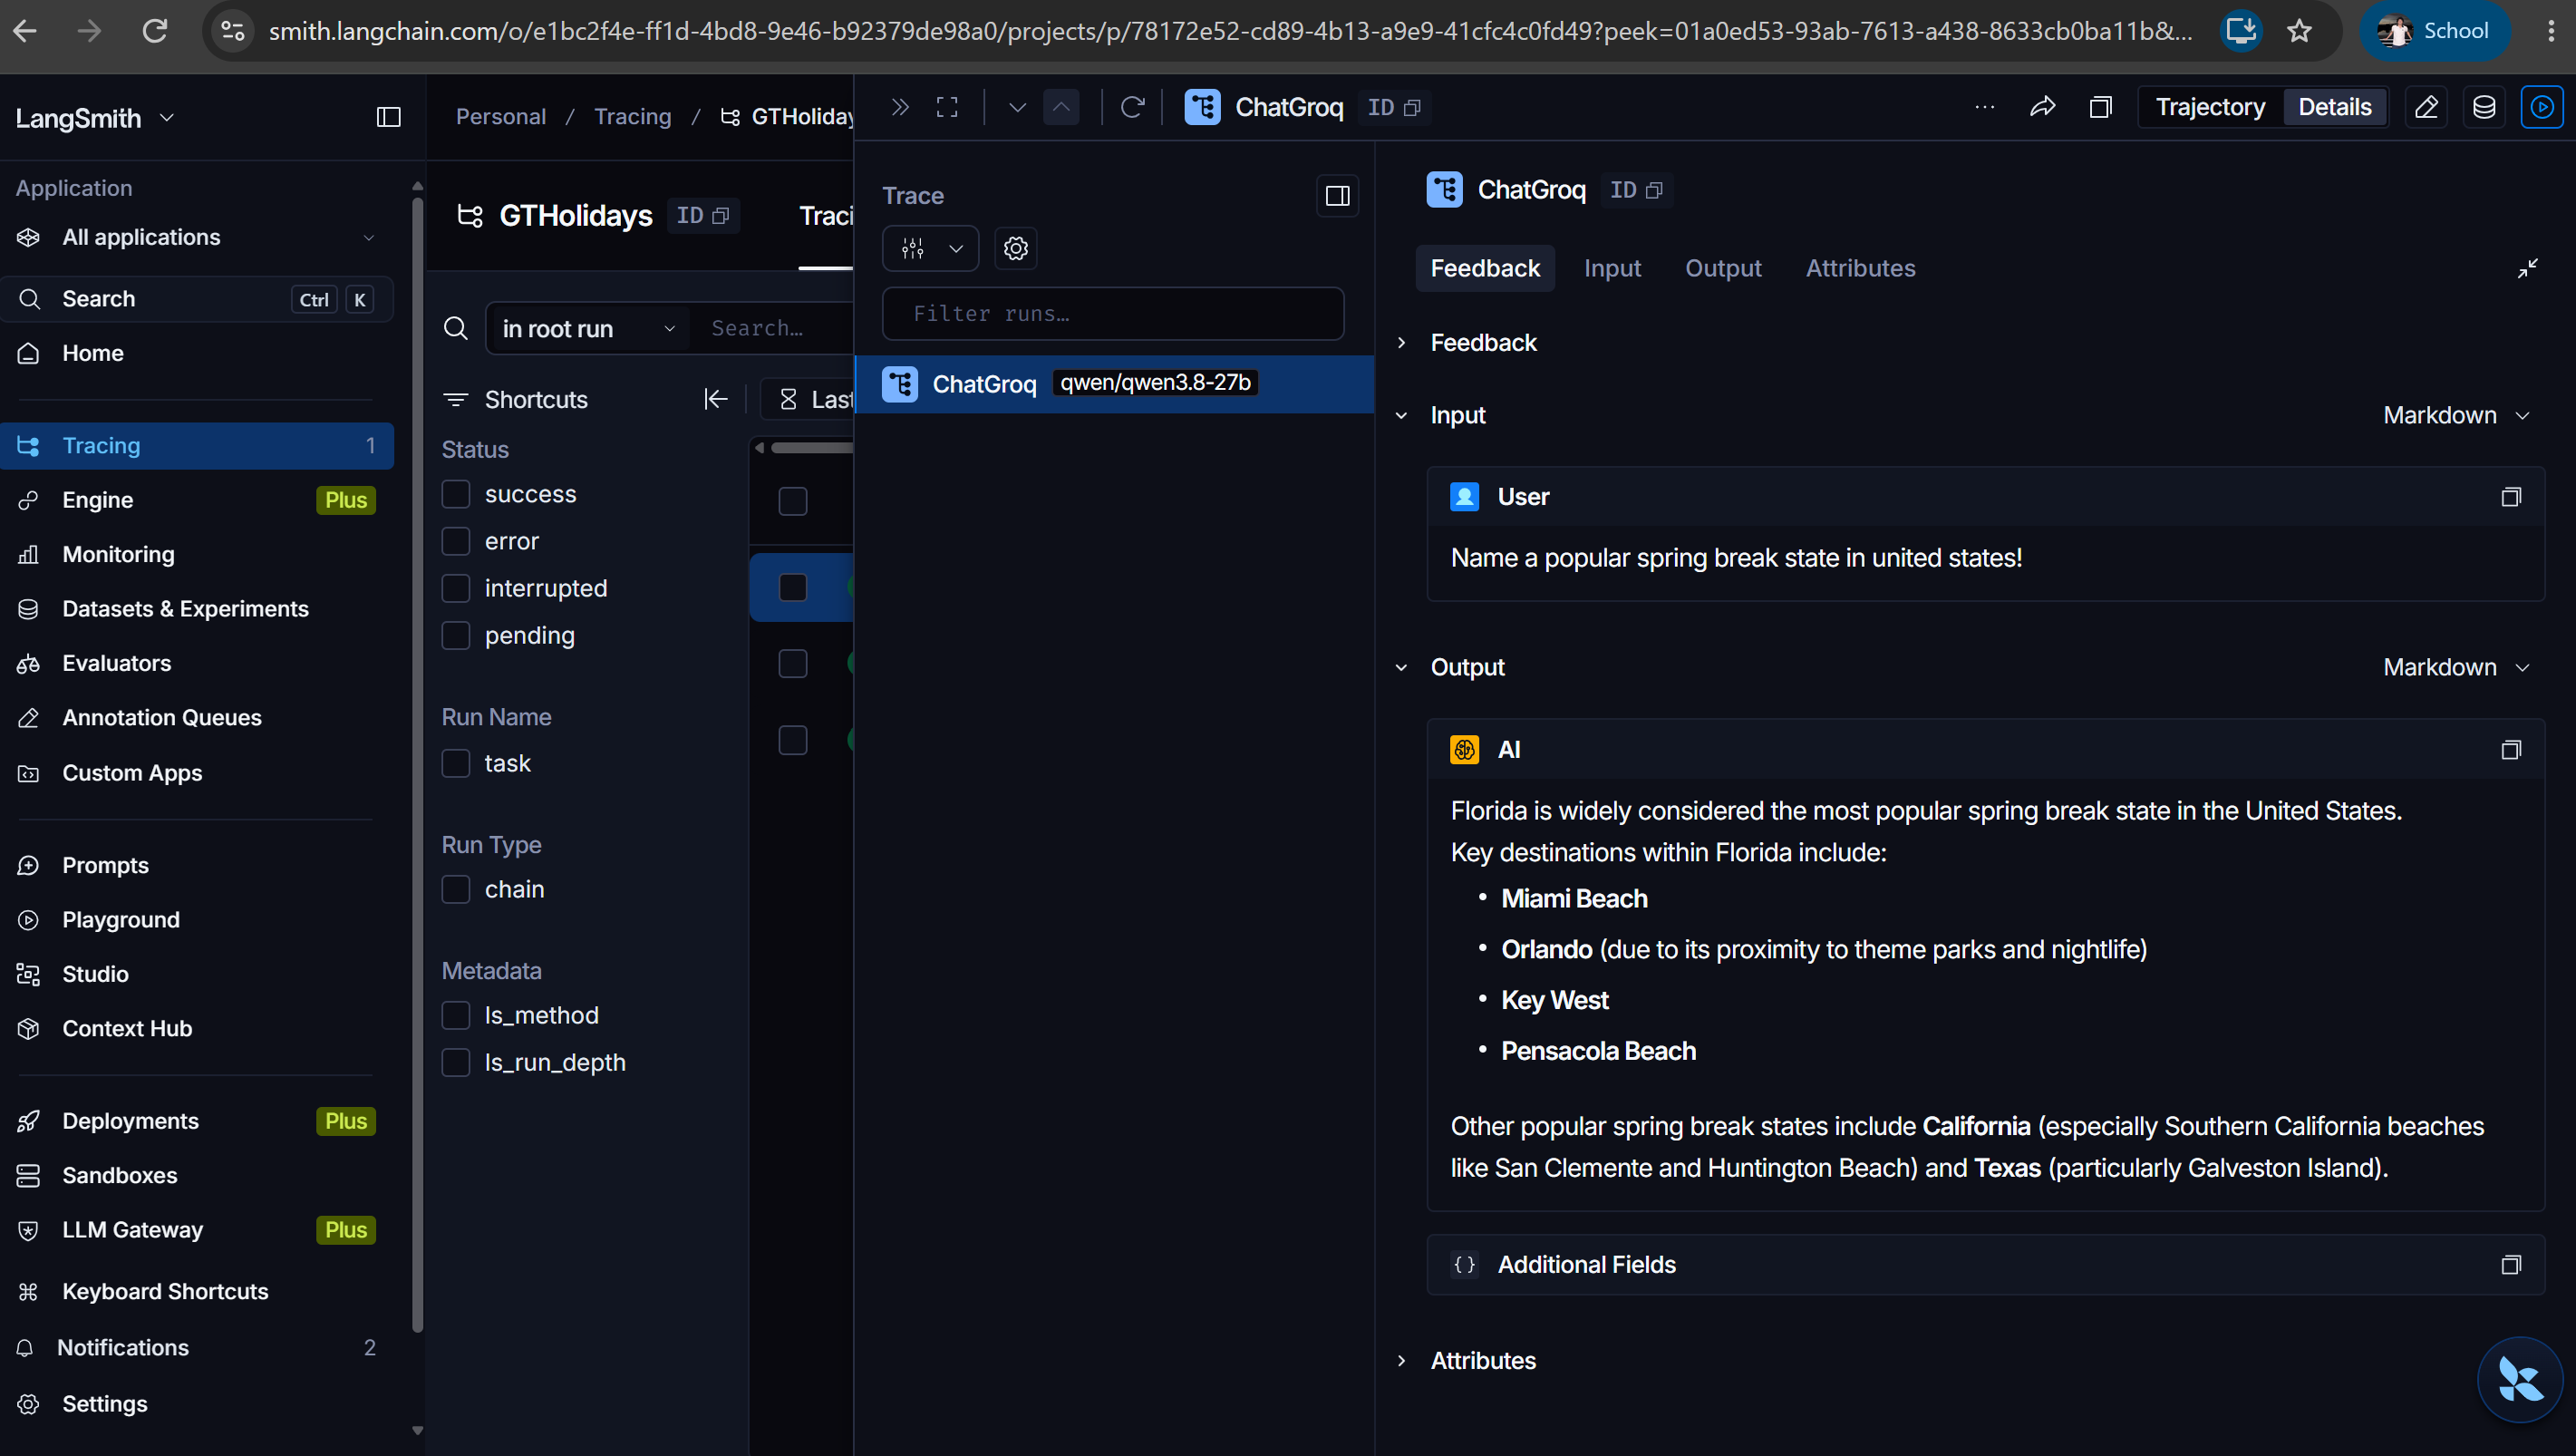

# Huggingface Model Setup

# 5. Data Design
○ You will use Pydantic to define a structured data schema for your agent to reason over.

■ This is a very important step that has impacts later on, so don’t skip.

■ Pydantic is the standard for LangChain to ensure structured LLM outputs and comes already
installed in Colab (else: pip install pydantic - docs)

● Note: Don’t confuse this with another Pydantic python package, pydantic-ai, which is an
agentic framework. We’ll just be using the validation and parsing package.

■ A schema is created by subclassing Pydantic’s BaseModel.
○ In a code cell, create a new class to represent the data you will need to perceive.

■ ex. class MovieUserState(BaseModel)
○ Add all the fields you would expect to receive in order to perform the agent’s goal.

■ ex. recently_watched: list[str] = Field(default_factory=list, description="Titles
the user has recently watched, if mentioned or visible")

■ ex. preferred_genres: list[str] = Field(default_factory=list, description="Genres
the user is in the mood for")

○ Be sure to indicate if each field is optional, a default value if appropriate, and a clear description
in words.

○ Please also include a field called unclear_fields so the model has a place to flag
low-confidence extractions.

■ ex. unclear_fields: list[str] = Field(...)
○ Example in the LangChain docs.


In [128]:
from typing import Optional, Literal
from pydantic import BaseModel, Field

LodgingType = Literal['hotel','motel','hostel','airbnb','stay_with_host']
Cuisine = Literal['italian','mexican','thai','chinese','indian','west asian']
RequestType = Literal['suggest_destination', 'plan_known_destination','undecided']
BreakPeriod = Literal['fall_break','spring_break','summer','winter_break','national_holidays','weekend']

class Traveler(BaseModel):
  """ Friend 1 in group and their starting point, budget, preference."""

  full_name: Optional[str] = Field(
      default=None, description="Friend's full name"
  )
  home_address: Optional[str] = Field(
      default=None, description = 'Home address exactly as provided'
  )
  home_state: Optional[str] = Field(
      default=None, description = 'U.S State'
  )
  home_city: Optional[str] = Field(
      default=None, description = 'City he starts from'
  )
  nearest_airport: Optional[str] = Field(
      default=None, description = '3 letter code of nearest airport'
  )
  can_host: Optional[bool] = Field(
      default=None, description = 'Whether this person can host the group at home.'
  )
  budget_min: Optional[float] = Field(
      default=None, description = 'least amount this person expects to spend..'
  )
  budget_max: Optional[float] = Field(
      default=None, description = 'Most this person can spend in total'
  )
  dietary_restrictions: list[str] = Field(
      default_factory=list, description = 'e.g vegetarian, vegan, no eggs, no meat, no nut'
  )
  cuisine_preferences: list[Cuisine] = Field(
      default_factory=list, description = 'Preferred cuisines, mapped to the 5 allowed categories'
  )
  lodging_preference: Optional[LodgingType] = Field(
      default=None, description = 'Preferred place to stay, if stated'
  )
  interests: list[str] = Field(
      default_factory=list, description = 'Activities this person enjoys'
  )
  notes: Optional[str] =  Field(
      default=None, description="This person's own thoughts or wishes"
  )

In [129]:
class GroupTripState(BaseModel):

  travelers: list[Traveler] = Field(
      default_factory=list, description = 'One entry per person mentioned'
  )
  group_size_stated: Optional[int] = Field(
      default = None, description = 'Number of people in group'
  )
  break_period: Optional[BreakPeriod] = Field(
      default = None, description= "Which break the trip is for"
  )
  start_date: Optional[str] = Field(
      default = None, description = 'YYYY-MM-DD trip start date'
  )
  end_date: Optional[str] = Field(
      default = None, description = 'YYYY-MM-DD trip end date'
  )
  num_days: Optional[int] = Field(
      default=None, description = 'Trip length in days'
  )
  request_type: RequestType = Field(
      default='undecided', description = 'suggest_destination if the group wants; plan_known_destination if they already chose where to go'
  )
  known_destination: Optional[str] = Field(
      default=None, description='The destination group already chose'
  )
  candidate_destinations: list[str] = Field(
      default_factory = list, description = 'Destinations the group is considering'
  )
  acceptable_lodging: list[LodgingType] = Field(
      default_factory = list , description = 'Lodging types the group prefers'
  )
  needs_car_rent: Optional[bool] = Field(
      default = None, description = "Whether group wants to rent a car"
  )
  cost_split_preference: Optional[Literal['equal','proportional','host_contributes_more','undecided']] = Field(
      default = None, description = "How the group wants to split the shared costs"
  )
  group_interests: list[str] = Field(
      default_factory=list, description='Activities the whole group wants'
  )
  things_to_avoid: list[str] = Field(
      default_factory = list, description="Things group wants to avoid"
  )
  additional_notes: Optional[str] = Field(
      default=None, description = "Other group thoughts not captured by any field"
  )
  unclear_fields: list[str] = Field(
      default_factory=list,
      description='Fields that are ambiguous, missing but important, or contradictor'
  )



In [130]:
print(GroupTripState.model_json_schema())

{'$defs': {'Traveler': {'description': 'Friend 1 in group and their starting point, budget, preference.', 'properties': {'full_name': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': "Friend's full name", 'title': 'Full Name'}, 'home_address': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Home address exactly as provided', 'title': 'Home Address'}, 'home_state': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'U.S State', 'title': 'Home State'}, 'home_city': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'City he starts from', 'title': 'Home City'}, 'nearest_airport': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': '3 letter code of nearest airport', 'title': 'Nearest Airport'}, 'can_host': {'anyOf': [{'type': 'boolean'}, {'type': 'null'}], 'default': None, 'description': 'Whether this person can host the group at h

# 6. Perception

# a) Instantiate and constrain model

In [166]:
from langsmith import traceable
from langchain_core.messages import SystemMessage, HumanMessage
TEXT_MODEL = 'openai/gpt-oss-120b'
text_llm = ChatGroq(model=TEXT_MODEL, temperature=0)
text_structured_model= text_llm.with_structured_output(GroupTripState, method='json_schema')
perception_llm = ChatGroq(model=VISION_MODEL, temperature=0)
structured_model = perception_llm.with_structured_output(GroupTripState)

# b) extraction instructions

In [167]:
extraction_instructions = """ You extracts group trip-planning into the given schema.

Rules:

1. Create one traveller entry per person mentioned. There can be any number of people.
2. Only fill fields the input supports. Leave unknown fields empty. Never guess.
3. Map cuisines to exactly these categories: italian,mexican,thai,chinese,indian,west asian, mediterranean.
4. If the group already chose a destination, set request_type to plan_known_destination and fill known_destination. If they want recommendation, use suggest_destination.
5. Summarize each person's own thoughts briefly in their notes field.
6. Add to unclear_fields anything vague, missing but important (home city, dates, budget, trip length) or contradictory, written as 'field_name: reason'.
"""

# c) clean and filter helpers

In [168]:
import re
from PIL import Image

def clean_text(raw_text: str) -> str:

  replacements = {"\u2013": "-", "\u2014": "-", "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"'}
  for old, new in replacements.items():
    raw_text = raw_text.replace(old, new)

  text = re.sub(r"[^\x00-\x7F]+", " ", raw_text)
  text = re.sub(r"\$(\d+(?:\.\d+)?)k\b", lambda m: f"${int(float(m.group(1))*1000)}", text, flags=re.I)

  return re.sub(r"\s+", " ", text).strip()

def filter_text(text: str) -> str:
  text = re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", "[EMAIL REMOVED]", text)
  text = re.sub(r"\b\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}","[PHONE REMOVED]", text)
  text = re.sub(r"\b(?:\d[ -]?){13,16}\b", "[CARD REMOVED]", text)

  return text

def filter_image(image_path: str, min_side: int=200, max_mb: float = 15) -> None:
  if os.path.getsize(image_path) / (1024*1024) > max_mb:
    raise ValueError('Image file is too large')
  try:
    with Image.open(image_path) as img:
      width, height = img.size
  except Exception:
    raise ValueError('File is not a readable image.')
  if min(width,height) < min_side:
    raise ValueError("Image is too small to read text from.")


def clean_image(image_path: str, max_side: int=1600) -> str:
  img = Image.open(image_path).convert("RGB")
  img.thumbnail((max_side, max_side))
  cleaned_path = "cleaned_" + os.path.splitext(os.path.basename(image_path))[0] + ".jpg"
  img.save(cleaned_path, "JPEG", quality=85)
  return cleaned_path

# d) Perception function 1 for Text

In [169]:
@traceable(name='perceive_text')
def perceive_text(raw_text: str) -> GroupTripState:
  text = filter_text(clean_text(raw_text))
  messages = [
      SystemMessage(content=extraction_instructions),
      HumanMessage(content=text)
  ]
  return text_structured_model.invoke(messages)

# e) perception fucntion 2: group chat screenshot

In [170]:
import base64, mimetypes

def encode_image(image_path: str) -> str:
  mime = mimetypes.guess_type(image_path)[0] or "image/jpeg"
  with open(image_path, "rb") as f:
    encoded = base64.b64encode(f.read()).decode('utf-8')
  return f'data:{mime};base64,{encoded}'

@traceable(name='perceive_chat_image')
def perceive_chat_image(image_path: str, context_note: str = "") -> GroupTripState:
  filter_image(image_path)
  cleaned_path = clean_image(image_path)
  content = [
      {"type": "text",
       "text": "This screenshot is a group chat about planning a break trip. Extrct each person's details and the group's plans"+ context_note},
      {"type": "image_url", "image_url": {"url": encode_image(image_path)}},
  ]
  messages = [
      SystemMessage(content=extraction_instructions),
      HumanMessage(content=content), ]
  return structured_model.invoke(messages)

# f) Test each function on easy input

In [171]:
def show_state(state: GroupTripState) -> None:
  print(state.model_dump_json(indent=3))

easy_text = """ Three friends are planning a spring break trip, March 13-March 19, 2027. We dont have a destination yet. Adithya Vardhan lives at 8 palm rd, Gainesville, Florida. His maximum budget $800 and minimum budget is $500. He is happy to host everyone at his place. He loves beaches and prefers hostels. Aniruddhan lives at 4324 Rowalt Dr, College Park, Maryland. His minimum budget is $600 and maximum budget is $800. He cannot host because of personal reasons. He enjoys museums and prefers cheap hotels. Vishaal lives in 45 lake Ave, Chicago, IL. Vishaal's minimum budget for trip is $650 and maximum budget is  $750.
.We are all vegetarian and love Indian, Chinese food. Adithy also likes Mediterranean food. As a group, we are okay with a cheap hotel, hostel or motel. We all like hiking, museums, beaches, and pubs. We want to split all costs equally. We want to avoid long road trips and very crowded tourist spots. We want to visit those hidden gem spots. We are not sure whther we need a rental car
"""

text_state = perceive_text(easy_text)
show_state(text_state)

{
   "travelers": [
      {
         "full_name": "Adithya Vardhan",
         "home_address": "8 palm rd, Gainesville, Florida",
         "home_state": "FL",
         "home_city": "Gainesville",
         "nearest_airport": null,
         "can_host": true,
         "budget_min": 500.0,
         "budget_max": 800.0,
         "dietary_restrictions": [
            "vegetarian"
         ],
         "cuisine_preferences": [
            "indian",
            "chinese"
         ],
         "lodging_preference": "hostel",
         "interests": [
            "beaches"
         ],
         "notes": "Wants to host, loves beaches, prefers hostels, vegetarian, likes Indian and Chinese food."
      },
      {
         "full_name": "Aniruddhan",
         "home_address": "4324 Rowalt Dr, College Park, Maryland",
         "home_state": "MD",
         "home_city": "College Park",
         "nearest_airport": null,
         "can_host": false,
         "budget_min": 600.0,
         "budget_max": 800.0,
    

In [172]:
path = '/content/trip_package_flyer.png'
chat_state = perceive_chat_image(path)
show_state(chat_state)

{
   "travelers": [],
   "group_size_stated": null,
   "break_period": null,
   "start_date": null,
   "end_date": null,
   "num_days": null,
   "request_type": "plan_known_destination",
   "known_destination": null,
   "candidate_destinations": [],
   "acceptable_lodging": [],
   "needs_car_rent": null,
   "cost_split_preference": null,
   "group_interests": [],
   "things_to_avoid": [],
   "additional_notes": null,
   "unclear_fields": [
      "travelers: no individual names, home cities, or per-person budgets provided",
      "group_size_stated: flyer says 'group of 3 or more' but exact number unknown",
      "cost_split_preference: not mentioned"
   ]
}


O/P Image:
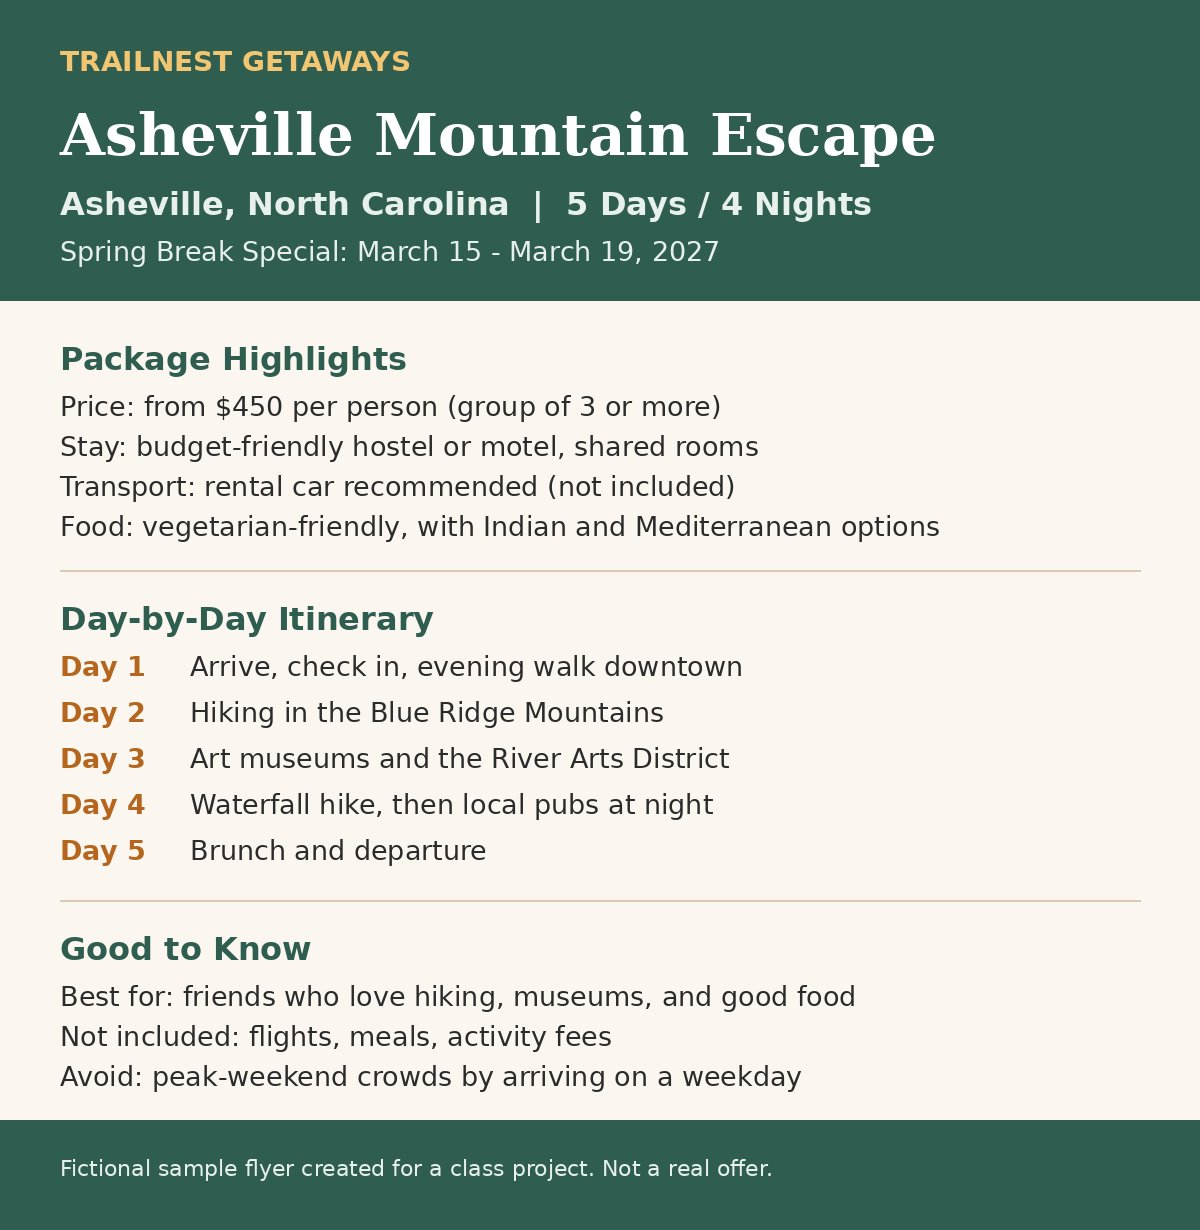

Step 7: Reasoning



# b) System Prompt

In [173]:
system_prompt = """
You are the trip-planning assistant for GTHolidays. You help groups of friends who live in different U.S cities plan affordable fall or spring break trips.
You will receive a structured JSON trip profile: each traveller's home city, nearest airport, budget range, food needs, oreferences and notes, plus group details and an unclear_fields list. Then you will receive the user's request.

How to respond:

Reasoning:
Think step by step and show your work.

1. Summarize what you know and what is missing. Review every item in unclear_friends.
2. Check for conflicts (budgets vs plans, hosting vs no space, equal split vs host  option).
3. If request_type is suggest_destination: compare candidate options, including each traveler's home city as a host option (only the others travel) and neutral cities
(everyone travels). For each, note who flies, lodging needs, car needs, and whether it fits every person's budget_max.

4. If request_type is plan_known_destination: check it fits budgets and trip length.


Answer:
If a critical detail is missing or contradictory, ask specific , clarifying questions one by one and then analyze well to give a tentative plan. Otherwise proide:

- Destination: your recommendation and why
- Flights: for each traveler, the route from their nearest airport and cost-saving tips.
- Lodging: the cheapest suitable type (hotel, motel, airbnb, or host's address).
- Food: what to look for in each of these cuisines: Indian, Mexican, Italian, East Asian, Chinese, respecting all dietary restrictions.
- itinerary: a day-by-day outline for the trip length.
- Checklist: things the group should book or confirm.

Constraints:
- Do not invent exact prices, flight numbers, or specific deals. Use relative comparisons, and say that live prices will be checked later.
- Only mention real cities and well-known real places. Do not make up restaurant names.
- Always respect dietary restrictions and every person's budget_max.

"""

# c) Create the agent

In [174]:
hf_token = userdata.get("HF_TOKEN")

In [175]:
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langchain.agents import create_agent

hf_endpoint = HuggingFaceEndpoint(repo_id = REASONING_MODEL, provider='auto', huggingfacehub_api_token=hf_token, temperature=0.2, max_new_tokens=2000)

reasoning_llm = ChatHuggingFace(llm=hf_endpoint)
agent = create_agent(model=reasoning_llm, tools=[], system_prompt=system_prompt)


# Create Agent explanation:

create_agent builds a small graph that runs a loop.

The state is list of messages. It adds your system prompt at the start.

The LLM is decision-maker. At each steo it reads messages and either calls a tool or gives a final answer.




In [176]:
# from langchain.agents import create_agent

# reasoning_llm = ChatGroq(model=REASONING_MODEL, temperature=0.2)

# agent = create_agent(
#     model=reasoning_llm,
#     tools=[],
#     system_prompt = system_prompt
# )

# d) Wrapping invoke function

In [177]:
@traceable(name='run_agent')
def run_agent(trip_state: GroupTripState, user_request: str) -> str:
  user_message = (
      "Trip profile: \n"+trip_state.model_dump_json(indent=2) + "\n\n User request: "+ user_request
  )

  result = agent.invoke(
      {"messages": [{'role': 'user', 'content': user_message}]}
  )

  final_message = result['messages'][-1]
  print("=== Model's reasoning....")
  print(final_message.content)
  return final_message.content

# e) Three hard test cases

Test 1: Ambiguous text

In [178]:
ambiguous_prompt = """
Four of us want to do something for fall break 2026 between 10th to 17th october. I'm near college park, vishaal's in chicago, adithya's near orlando and pallavi is in texas.
Somewhere in the middle would be nice, maybe for those 7-8 days, cheap-ish. Good veg food is a must, maybe Asian food?
"""

state_1 = perceive_text(ambiguous_prompt)
show_state(state_1)

answer_1 = run_agent(state_1, "Where should we go, and how should we plan it?")
print(answer_1)

{
   "travelers": [],
   "group_size_stated": null,
   "break_period": null,
   "start_date": null,
   "end_date": null,
   "num_days": null,
   "request_type": "undecided",
   "known_destination": null,
   "candidate_destinations": [],
   "acceptable_lodging": [],
   "needs_car_rent": null,
   "cost_split_preference": null,
   "group_interests": [],
   "things_to_avoid": [],
   "additional_notes": null,
   "unclear_fields": []
}
=== Model's reasoning....
**What I know so far**

| Item | Current value |
|------|---------------|
| Travelers | **None listed** – I don’t know who is in the group, where they live, their budgets, dietary needs, or any special preferences. |
| Group size | Not provided |
| Break period (fall or spring) | Not provided |
| Dates / length of trip | Not provided |
| Request type | “undecided” – you haven’t chosen a destination yet. |
| Candidate destinations | None |
| Acceptable lodging types | None |
| Car‑rental need | Not provided |
| Cost‑split preference | 

# Explanation for Test 1:

Perception returned an empty state with no travelers due to unclear fields, even though the input named four people adn cities.

The agent correctly noticed it had nothing to work wih and asked for clarifying questions, instead of inventing a trip.

# Test 2: Missing information

In [179]:
path = '/content/trip_package_flyer.png'
with traced():
  state_2 = perceive_chat_image(path, context_note = 'There are 4 of us. Adithya is in Gainesville, Florida. Vishaal is in Chicago')
  show_state(state_2)

answer_2 = run_agent(state_2, "Plan this trip for our group for least total cost ")
print(answer_2)

{
   "travelers": [],
   "group_size_stated": null,
   "break_period": null,
   "start_date": null,
   "end_date": null,
   "num_days": null,
   "request_type": "plan_known_destination",
   "known_destination": null,
   "candidate_destinations": [],
   "acceptable_lodging": [],
   "needs_car_rent": null,
   "cost_split_preference": null,
   "group_interests": [],
   "things_to_avoid": [],
   "additional_notes": null,
   "unclear_fields": [
      "travelers: only 2 of 4 group members named (Adithya, Vishaal); the other 2 are unknown",
      "travelers: home cities/states missing for the 2 unnamed members",
      "travelers: budgets not provided for any member",
      "group_interests: inferred from the flyer (hiking, museums, food) but not explicitly stated by the group"
   ]
}
=== Model's reasoning....
**What I know so far**

| Item | Details |
|------|---------|
| Travelers listed | Only **Adithya** and **Vishaal** are named. |
| Travelers missing | 2 group members (names, home cities

# Test 2 explanation:

Perception noticed Adithya and Vishaal and missing members in unclear fields, but didnt create traveler for them, it missed the destination and dates from the flyer.

The agent correctly listed what was missing and asked clarifying questions, owning to the structured prompt template, where  it has been told not to assume any information and ask clarifying questions step by step.

Good caution from the agent, it has asked many questions at once.

# Test 3: Contradictory (text)

In [181]:
contradictory_input = """
Three of us want to go to Miami for spring break, 7 days. Rahul is in college park and can host us. Vishaal is in chicago and adithya's in tampa. Each of us can spend at most $250 total, and we want a nnice beachfront hotel. We want to split everything exactly equally. Also, Rahul's apartment is too small for guests. Actually, maybe we should just stay in Maryland instead
"""
state_3 = perceive_text(contradictory_input)
show_state(state_3)

answer_3 = run_agent(state_3, "Plan our trips with flights, lodging, food and an intinerary.")
print(answer_3)

{
   "travelers": [
      {
         "full_name": "Rahul",
         "home_address": null,
         "home_state": "MD",
         "home_city": "College Park",
         "nearest_airport": null,
         "can_host": null,
         "budget_min": null,
         "budget_max": 250.0,
         "dietary_restrictions": [],
         "cuisine_preferences": [],
         "lodging_preference": null,
         "interests": [],
         "notes": "Wants to host but apartment too small for guests."
      },
      {
         "full_name": "Vishaal",
         "home_address": null,
         "home_state": "IL",
         "home_city": "Chicago",
         "nearest_airport": null,
         "can_host": null,
         "budget_min": null,
         "budget_max": 250.0,
         "dietary_restrictions": [],
         "cuisine_preferences": [],
         "lodging_preference": null,
         "interests": [],
         "notes": null
      },
      {
         "full_name": "Adithya",
         "home_address": null,
         "home

# Test 3 Explanation

Perceptionn did well here. It flagged Miami vs Maryland conflict and the hostinf conflict.

The agent only asked about the dates. It ignored bigger contradictions $250 versus week at beachfront hotel. hostinf versus too small, and Miami versus Maryland. It also skipped the Reasoning/Answer headings.

This is a bit weak respose. Dates matter less than whether the trip is even possible on $250. A fix be a prompt rule to resolve contradictions before asking details.